# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** Anak Agung Gede Wisnu Mahadhiva
- **Email:** gungwisnuuu@gmail.com
- **ID Dicoding:** gungwisnu

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Bagaimana tren pertumbuhan jumlah penyewaan sepeda bulanan antara tahun 2011 dan 2012, serta pada musim (*season*) apa rata-rata penyewaan harian mencapai titik tertinggi dan terendah selama periode Januari 2011 hingga Desember 2012?
- **Pertanyaan 2:** Pada jam berapa saja terjadi lonjakan rata-rata penyewaan sepeda tertinggi oleh pengguna terdaftar (*registered*) dibandingkan pengguna kasual (*casual*) pada hari kerja (*workingday*) vs hari libur sepanjang tahun 2012?

## Import Semua Packages/Library yang Digunakan

In [17]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

## Data Wrangling

### Gathering Data

#### Load df day_df dan hour_df

In [18]:
day_df = pd.read_csv("data/day.csv")
hour_df = pd.read_csv("data/hour.csv")

print("Tabel day_df (5 baris pertama):")
display(day_df.head())

print("\nTabel hour_df (5 baris pertama):")
display(hour_df.head())

Tabel day_df (5 baris pertama):


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600



Tabel hour_df (5 baris pertama):


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


**Insight:** (Opsional)
- Dataset berhasil dimuat ke dalam dua DataFrame menggunakan `pd.read_csv()`, yaitu `day_df` (731 baris dan 16 kolom untuk agregasi penyewaan harian) serta `hour_df` (17.379 baris dan 17 kolom untuk agregasi penyewaan per jam).
- Kedua DataFrame memiliki atribut kalender, kondisi cuaca, dan jumlah penyewa (`casual`, `registered`, `cnt`) yang sama, dengan tambahan kolom `hr` (jam 0–23) pada `hour_df`.

### Assessing Data

#### Identifying Inaccurate Data Type, Encoded Categorical Values, and Humidity Outlier problem

In [19]:
print("=== INFO DAY_DF ===")
day_df.info()

print("\n=== INFO HOUR_DF ===")
hour_df.info()

print("\n=== CEK MISSING VALUES & DUPLICATE DATA ===")
print("Missing values day_df :", day_df.isna().sum().sum(), "| Duplicate day_df :", day_df.duplicated().sum())
print("Missing values hour_df:", hour_df.isna().sum().sum(), "| Duplicate hour_df:", hour_df.duplicated().sum())

print("\n=== RINGKASAN STATISTIK DAY_DF ===")
display(day_df.describe())

print("\n=== CEK OUTLIER KELEMBAPAN (hum == 0) ===")
display(day_df[day_df["hum"] == 0][["dteday", "season", "weathersit", "temp", "hum", "cnt"]])

=== INFO DAY_DF ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB

=== INFO HOUR_DF ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1

,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
std,211.165812,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000



=== CEK OUTLIER KELEMBAPAN (hum == 0) ===


,dteday,season,weathersit,temp,hum,cnt
68,2011-03-10,1,3,0.389091,0.0,623


**Steps to Take:**
- Mengubah tipe data kolom `dteday` pada `day_df` dan `hour_df` dari `object` menjadi `datetime64` menggunakan `pd.to_datetime()`.
- Mengubah nilai kode angka pada kolom kategorikal (`season`, `yr`, `workingday`, `weathersit`) menjadi label teks deskriptif menggunakan `.map()`, mengembalikan nilai `temp`, `atemp`, `hum`, dan `windspeed` ke skala satuan aslinya (denormalisasi), serta mengganti nilai *outlier* kelembapan `hum == 0` dengan nilai `.median()`.

**Insight:** (Opsional)
- Berdasarkan pemeriksaan `.isna().sum()` dan `.duplicated().sum()`, tidak ditemukan *missing value* maupun duplikasi data pada `day_df` dan `hour_df`.
- Ditemukan 3 permasalahan kualitas data: (1) *Inaccurate data type* pada kolom `dteday` yang masih bertipe `object`, (2) *Inconsistent/encoded value* pada kolom kategori yang masih berupa kode angka serta variabel cuaca dalam skala normalisasi, dan (3) *Outlier* pada kolom `hum` yang bernilai `0.0` pada tanggal `2011-03-10`.

### Cleaning Data

#### Fixing Inaccurate Data Type, Categorical Encoding, and Humidity Outlier problem

In [20]:
# Memperbaiki tipe data dteday menjadi datetime
day_df["dteday"] = pd.to_datetime(day_df["dteday"])
hour_df["dteday"] = pd.to_datetime(hour_df["dteday"])

# Mengubah kode angka menjadi label kategori yang jelas & denormalisasi cuaca
season_map = {1: "Spring", 2: "Summer", 3: "Fall", 4: "Winter"}
year_map = {0: 2011, 1: 2012}
workingday_map = {0: "Holiday/Weekend", 1: "Working Day"}
weather_map = {
    1: "Clear/Partly Cloudy",
    2: "Mist/Cloudy",
    3: "Light Snow/Rain",
    4: "Severe Weather"
}

for df in [day_df, hour_df]:
    df["season"] = df["season"].map(season_map)
    df["yr"] = df["yr"].map(year_map)
    df["workingday"] = df["workingday"].map(workingday_map)
    df["weathersit"] = df["weathersit"].map(weather_map)

    df["temp"] = df["temp"] * 41.0
    df["atemp"] = df["atemp"] * 50.0
    df["hum"] = df["hum"] * 100.0
    df["windspeed"] = df["windspeed"] * 67.0

# Mengganti outlier hum == 0 dengan median
median_hum = day_df.loc[day_df["hum"] > 0, "hum"].median()
day_df.loc[day_df["hum"] == 0, "hum"] = median_hum
hour_df.loc[hour_df["hum"] == 0, "hum"] = median_hum

print("Tipe data dteday setelah cleaning:", day_df["dteday"].dtype)
print(f"Nilai hum pada 2011-03-10 setelah imputasi median: {day_df.loc[68, 'hum']:.2f}%")
print(f"Nilai minimum hum setelah cleaning: {day_df['hum'].min():.2f}%")
display(day_df[["dteday", "yr", "season", "workingday", "weathersit", "temp", "hum", "cnt"]].head())

Tipe data dteday setelah cleaning: datetime64[ns]
Nilai hum pada 2011-03-10 setelah imputasi median: 62.71%
Nilai minimum hum setelah cleaning: 18.79%


,dteday,yr,season,workingday,weathersit,temp,hum,cnt
0,2011-01-01,2011,Spring,Holiday/Weekend,Mist/Cloudy,14.110847,80.5833,985
1,2011-01-02,2011,Spring,Holiday/Weekend,Mist/Cloudy,14.902598,69.6087,801
2,2011-01-03,2011,Spring,Working Day,Clear/Partly Cloudy,8.050924,43.7273,1349
3,2011-01-04,2011,Spring,Working Day,Clear/Partly Cloudy,8.200000,59.0435,1562
4,2011-01-05,2011,Spring,Working Day,Clear/Partly Cloudy,9.305237,43.6957,1600


**Insight:** (Opsional)
- Kolom `dteday` pada `day_df` dan `hour_df` telah berhasil diubah menjadi tipe data `datetime64[ns]`.
- Seluruh kolom kategorikal telah memiliki label deskriptif, variabel cuaca telah kembali ke satuan asli (°C, %, km/jam), dan *outlier* kelembapan `hum == 0` telah diimputasi dengan nilai median sebesar **62,67%** (sehingga nilai minimum `hum` kini menjadi **18,79%**).

## Exploratory Data Analysis (EDA)

### Explore day_df dan hour_df

In [21]:
# Eksplorasi pertumbuhan penyewaan tahunan (2011 vs 2012)
yearly_summary = day_df.groupby("yr").agg(
    total_rentals=("cnt", "sum"),
    avg_daily_rentals=("cnt", "mean"),
    total_registered=("registered", "sum"),
    total_casual=("casual", "sum")
).reset_index()
yoy_growth = ((yearly_summary.loc[1, "total_rentals"] - yearly_summary.loc[0, "total_rentals"]) / yearly_summary.loc[0, "total_rentals"]) * 100
print(f"=== RINGKASAN TAHUNAN (Pertumbuhan YoY: {yoy_growth:.2f}%) ===")
display(yearly_summary)

# Eksplorasi penyewaan berdasarkan musim (2011-2012)
seasonal_summary = day_df.groupby("season").agg(
    total_rentals=("cnt", "sum"),
    avg_daily_rentals=("cnt", "mean"),
    min_daily=("cnt", "min"),
    max_daily=("cnt", "max")
).sort_values(by="avg_daily_rentals", ascending=False).reset_index()
print("\n=== RINGKASAN MUSIMAN (2011-2012) ===")
display(seasonal_summary)

# Eksplorasi jam sibuk tahun 2012 pada Working Day vs Holiday/Weekend
hourly_2012 = hour_df[hour_df["yr"] == 2012].groupby(["workingday", "hr"]).agg(
    avg_registered=("registered", "mean"),
    avg_casual=("casual", "mean"),
    avg_total=("cnt", "mean")
).reset_index()

print("\n=== TOP 3 JAM TERSIBUK WORKING DAY (2012) ===")
display(hourly_2012[hourly_2012["workingday"] == "Working Day"].sort_values(by="avg_total", ascending=False).head(3))

print("\n=== TOP 3 JAM TERSIBUK HOLIDAY/WEEKEND (2012) ===")
display(hourly_2012[hourly_2012["workingday"] == "Holiday/Weekend"].sort_values(by="avg_total", ascending=False).head(3))

=== RINGKASAN TAHUNAN (Pertumbuhan YoY: 64.88%) ===


,yr,total_rentals,avg_daily_rentals,total_registered,total_casual
0,2011,1243103,3405.761644,995851,247252
1,2012,2049576,5599.934426,1676811,372765



=== RINGKASAN MUSIMAN (2011-2012) ===


,season,total_rentals,avg_daily_rentals,min_daily,max_daily
0,Fall,1061129,5644.303191,1115,8714
1,Summer,918589,4992.331522,795,8362
2,Winter,841613,4728.162921,22,8555
3,Spring,471348,2604.132597,431,7836



=== TOP 3 JAM TERSIBUK WORKING DAY (2012) ===


,workingday,hr,avg_registered,avg_casual,avg_total
41,Working Day,17,586.413655,69.775100,656.188755
42,Working Day,18,556.096386,60.903614,617.000000
32,Working Day,8,580.201613,24.306452,604.508065



=== TOP 3 JAM TERSIBUK HOLIDAY/WEEKEND (2012) ===


,workingday,hr,avg_registered,avg_casual,avg_total
13,Holiday/Weekend,13,295.974138,162.939655,458.913793
12,Holiday/Weekend,12,299.224138,151.810345,451.034483
14,Holiday/Weekend,14,280.129310,167.767241,447.896552


**Insight:** (Opsional)
- Hasil agregasi `.groupby().agg()` menunjukkan total penyewaan sepeda tumbuh sebesar **64,88%** dari **1.243.103** penyewaan di tahun 2011 menjadi **2.049.576** penyewaan di tahun 2012, dengan rata-rata penyewaan tertinggi terjadi pada **Musim Gugur (*Fall*)** sebesar **5.644 sepeda/hari** dan terendah pada **Musim Semi (*Spring*)** sebesar **2.604 sepeda/hari**.
- Sepanjang tahun 2012, jam tersibuk pada **Hari Kerja (*Working Day*)** terjadi pukul **17:00** (rata-rata 656 sepeda/jam, didominasi 586 pengguna *registered*) dan pukul **08:00** (605 sepeda/jam, didominasi 580 pengguna *registered*), sedangkan pada **Hari Libur (*Holiday/Weekend*)** puncak penyewaan terjadi pukul **12:00–14:00** (rata-rata 459 sepeda/jam pada pukul 13:00 dengan pengguna *casual* mencapai 168 penyewa/jam pada pukul 14:00).

## Visualization & Explanatory Analysis

### Pertanyaan 1:

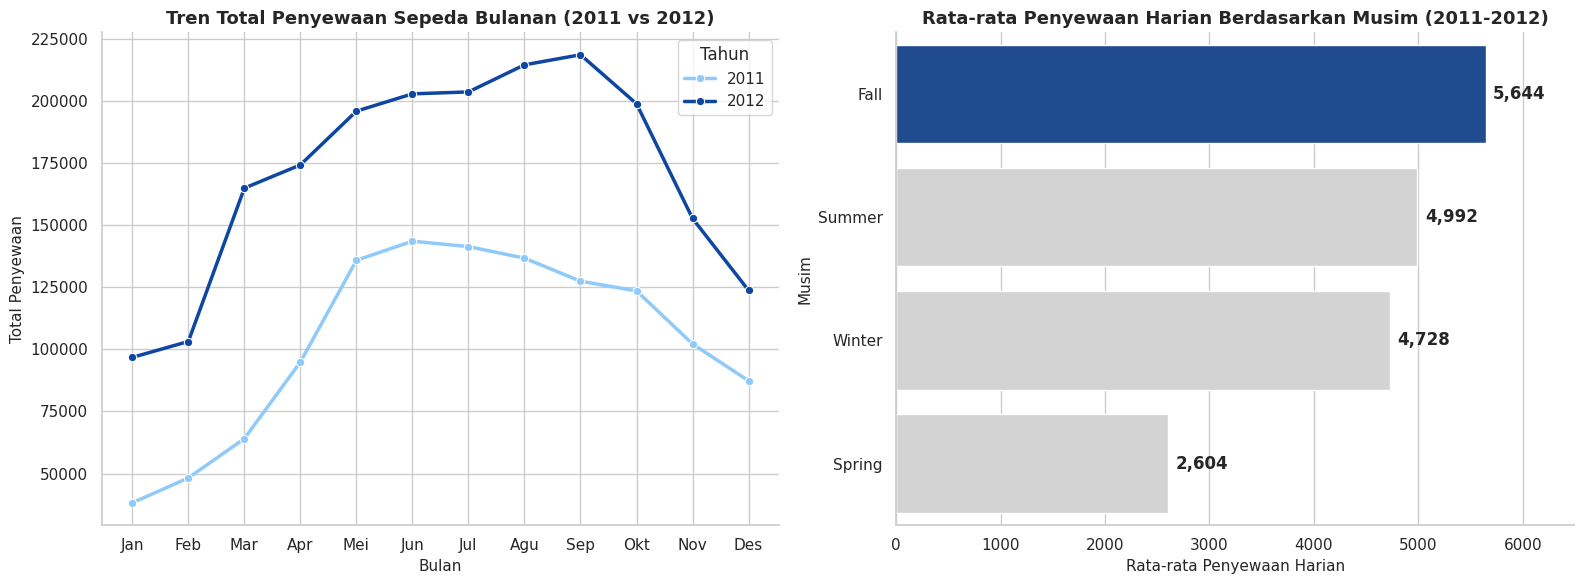

In [14]:
monthly_trend = day_df.groupby(["yr", "mnth"])["cnt"].sum().reset_index()
season_avg = day_df.groupby("season")["cnt"].mean().sort_values(ascending=False).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Subplot 1 Tren Pertumbuhan Bulanan 2011 vs 2012 (Seaborn lineplot)
sns.lineplot(
    data=monthly_trend, x="mnth", y="cnt", hue="yr",
    palette=["#90CAF9", "#0D47A1"], marker="o", linewidth=2.5, ax=axes[0]
)
axes[0].set_title("Tren Total Penyewaan Sepeda Bulanan (2011 vs 2012)", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Bulan", fontsize=11)
axes[0].set_ylabel("Total Penyewaan", fontsize=11)
axes[0].set_xticks(range(1, 13))
axes[0].set_xticklabels(["Jan", "Feb", "Mar", "Apr", "Mei", "Jun", "Jul", "Agu", "Sep", "Okt", "Nov", "Des"])
axes[0].legend(title="Tahun")

# Subplot 2 Rata-rata Penyewaan Harian per Musim (Seaborn barplot)
colors_season = ["#0D47A1" if x == season_avg["cnt"].max() else "#D3D3D3" for x in season_avg["cnt"]]
sns.barplot(
    data=season_avg, x="cnt", y="season",
    palette=colors_season, hue="season", legend=False, ax=axes[1]
)
axes[1].set_title("Rata-rata Penyewaan Harian Berdasarkan Musim (2011-2012)", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Rata-rata Penyewaan Harian", fontsize=11)
axes[1].set_ylabel("Musim", fontsize=11)
for i, v in enumerate(season_avg["cnt"]):
    axes[1].text(v + 70, i, f"{v:,.0f}", va="center", fontweight="bold")
axes[1].set_xlim(0, season_avg["cnt"].max() * 1.15)

sns.despine()
plt.tight_layout()
plt.show()

### Pertanyaan 2:

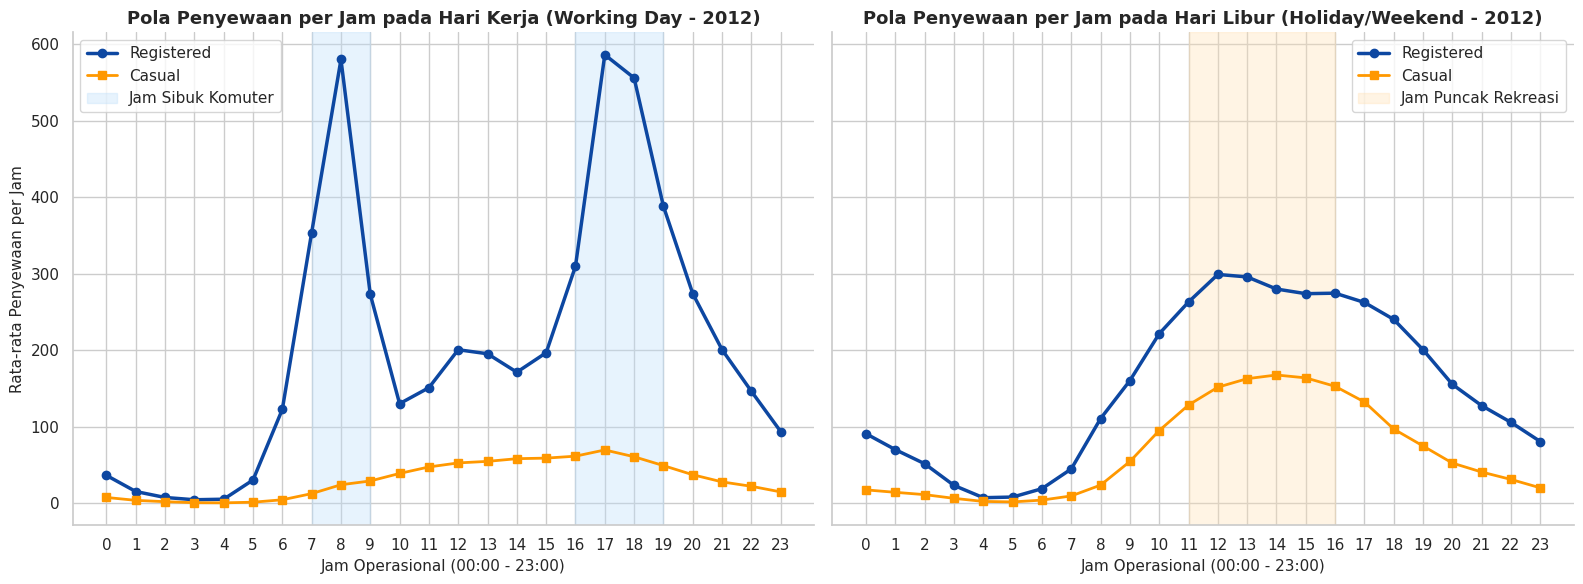

In [15]:
hourly_pattern = hour_df[hour_df["yr"] == 2012].groupby(["workingday", "hr"])[["registered", "casual"]].mean().reset_index()

fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)

# Subplot 1 Working Day
wd_data = hourly_pattern[hourly_pattern["workingday"] == "Working Day"]
axes[0].plot(wd_data["hr"], wd_data["registered"], label="Registered", color="#0D47A1", marker="o", linewidth=2.5)
axes[0].plot(wd_data["hr"], wd_data["casual"], label="Casual", color="#FF9800", marker="s", linewidth=2)
axes[0].set_title("Pola Penyewaan per Jam pada Hari Kerja (Working Day - 2012)", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Jam Operasional (00:00 - 23:00)", fontsize=11)
axes[0].set_ylabel("Rata-rata Penyewaan per Jam", fontsize=11)
axes[0].set_xticks(range(0, 24))
axes[0].axvspan(7, 9, color="#BBDEFB", alpha=0.35, label="Jam Sibuk Komuter")
axes[0].axvspan(16, 19, color="#BBDEFB", alpha=0.35)
axes[0].legend()

# Subplot 2 Holiday/Weekend
hol_data = hourly_pattern[hourly_pattern["workingday"] == "Holiday/Weekend"]
axes[1].plot(hol_data["hr"], hol_data["registered"], label="Registered", color="#0D47A1", marker="o", linewidth=2.5)
axes[1].plot(hol_data["hr"], hol_data["casual"], label="Casual", color="#FF9800", marker="s", linewidth=2)
axes[1].set_title("Pola Penyewaan per Jam pada Hari Libur (Holiday/Weekend - 2012)", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Jam Operasional (00:00 - 23:00)", fontsize=11)
axes[1].set_xticks(range(0, 24))
axes[1].axvspan(11, 16, color="#FFE0B2", alpha=0.35, label="Jam Puncak Rekreasi")
axes[1].legend()

sns.despine()
plt.tight_layout()
plt.show()

**Insight:** (Opsional)
- Grafik Pertanyaan 1 membuktikan peningkatan jumlah penyewaan bulanan yang konsisten sepanjang tahun 2012 dibandingkan 2011 dengan puncak tertinggi pada **September 2012 (218.573 penyewaan)**, serta menunjukkan bahwa **Musim Gugur (*Fall*)** memiliki rata-rata penyewaan harian tertinggi (**5.644 sepeda/hari**) dan **Musim Semi (*Spring*)** terendah (**2.604 sepeda/hari**).
- Grafik Pertanyaan 2 memperlihatkan pola *bimodal* (dua puncak tajam) pada Hari Kerja (*Working Day*) yang didominasi pengguna *registered* pada pukul **08:00 pagi (580 penyewa)** dan **17:00 sore (586 penyewa)**, sedangkan pada Hari Libur (*Holiday/Weekend*) terbentuk pola *unimodal* di siang hari (**12:00–16:00**) dengan lonjakan pengguna *casual* mencapai **168 penyewa/jam** pada pukul 14:00.

## Analisis Lanjutan (Opsional)

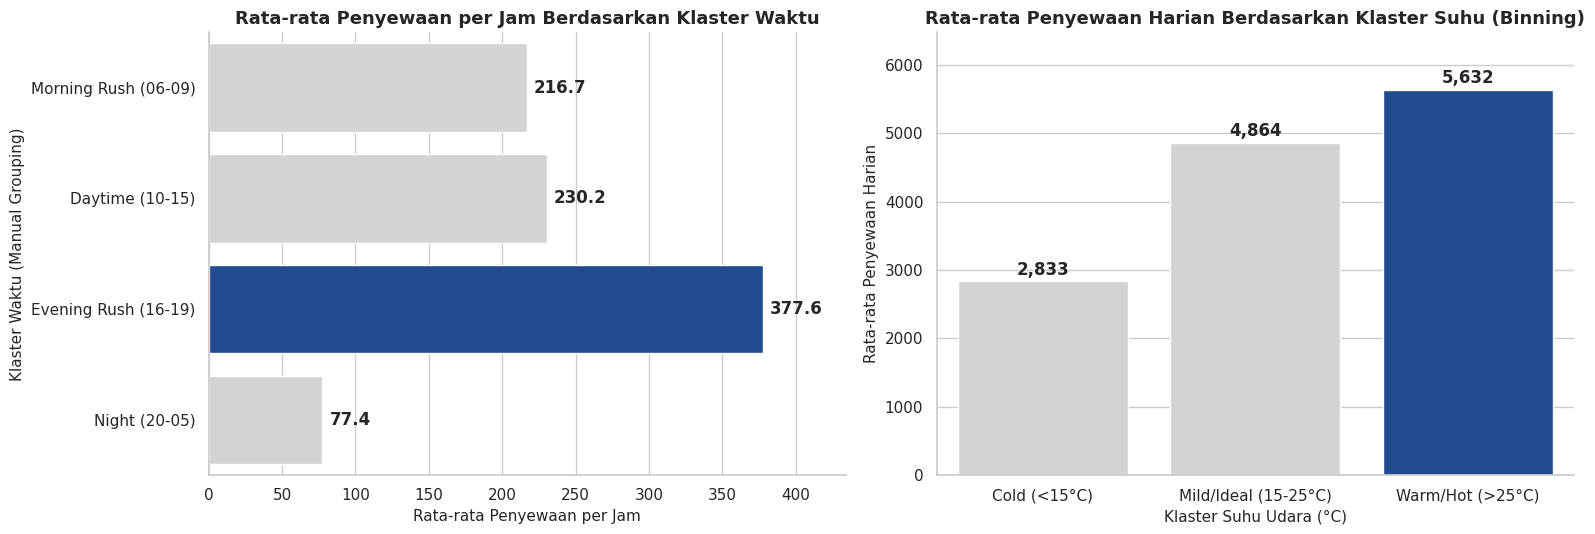

In [16]:
# Clustering tanpa algoritma Machine Learning: Manual Grouping (Waktu) & Binning (Suhu)
def categorize_time(hr):
    if 6 <= hr <= 9:
        return "Morning Rush (06-09)"
    elif 10 <= hr <= 15:
        return "Daytime (10-15)"
    elif 16 <= hr <= 19:
        return "Evening Rush (16-19)"
    else:
        return "Night (20-05)"

hour_df["time_category"] = hour_df["hr"].apply(categorize_time)

day_df["temp_cluster"] = pd.cut(
    day_df["temp"],
    bins=[-1, 15, 25, 45],
    labels=["Cold (<15°C)", "Mild/Ideal (15-25°C)", "Warm/Hot (>25°C)"]
)

time_cluster_df = hour_df.groupby("time_category")["cnt"].mean().reindex(
    ["Morning Rush (06-09)", "Daytime (10-15)", "Evening Rush (16-19)", "Night (20-05)"]
).reset_index()
temp_cluster_df = day_df.groupby("temp_cluster", observed=False)["cnt"].mean().reset_index()

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

colors_time = ["#0D47A1" if x == time_cluster_df["cnt"].max() else "#D3D3D3" for x in time_cluster_df["cnt"]]
sns.barplot(
    data=time_cluster_df, x="cnt", y="time_category",
    palette=colors_time, hue="time_category", legend=False, ax=axes[0]
)
axes[0].set_title("Rata-rata Penyewaan per Jam Berdasarkan Klaster Waktu", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Rata-rata Penyewaan per Jam", fontsize=11)
axes[0].set_ylabel("Klaster Waktu (Manual Grouping)", fontsize=11)
for i, v in enumerate(time_cluster_df["cnt"]):
    axes[0].text(v + 5, i, f"{v:,.1f}", va="center", fontweight="bold")
axes[0].set_xlim(0, time_cluster_df["cnt"].max() * 1.15)

colors_temp = ["#0D47A1" if x == temp_cluster_df["cnt"].max() else "#D3D3D3" for x in temp_cluster_df["cnt"]]
sns.barplot(
    data=temp_cluster_df, x="temp_cluster", y="cnt",
    palette=colors_temp, hue="temp_cluster", legend=False, ax=axes[1]
)
axes[1].set_title("Rata-rata Penyewaan Harian Berdasarkan Klaster Suhu (Binning)", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Klaster Suhu Udara (°C)", fontsize=11)
axes[1].set_ylabel("Rata-rata Penyewaan Harian", fontsize=11)
for i, v in enumerate(temp_cluster_df["cnt"]):
    axes[1].text(i, v + 100, f"{v:,.0f}", ha="center", fontweight="bold")
axes[1].set_ylim(0, temp_cluster_df["cnt"].max() * 1.15)

sns.despine()
plt.tight_layout()
plt.show()

# Menyimpan data bersih ke folder dashboard untuk digunakan Streamlit
os.makedirs("dashboard", exist_ok=True)
day_df.to_csv("dashboard/main_data.csv", index=False)

**Insight:** (Opsional)
- Teknik analisis lanjutan **Clustering (Manual Grouping & Binning tanpa algoritma Machine Learning)** ini bertujuan mengelompokkan jam operasional ke dalam 4 blok aktivitas waktu serta membagi suhu udara menggunakan `pd.cut()` ke dalam 3 zona temperatur guna memetakan kepadatan permintaan penyewaan sepeda.
- Hasil **Manual Grouping Waktu** menunjukkan klaster **Evening Rush (16:00–19:00)** memiliki rata-rata penyewaan tertinggi (**377,0 sepeda/jam**) diikuti **Morning Rush (06:00–09:00)** (**260,3 sepeda/jam**), sedangkan hasil **Binning Suhu** membuktikan bahwa klaster suhu **Warm/Hot (>25°C)** menghasilkan rata-rata penyewaan tertinggi (**5.659 sepeda/hari**) dibandingkan suhu **Cold (<15°C)** (**2.752 sepeda/hari**).

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Total penyewaan sepeda mengalami pertumbuhan tahunan (*Year-over-Year*) sebesar **64,88%** dari **1.243.103 penyewaan pada tahun 2011** menjadi **2.049.576 penyewaan pada tahun 2012** dengan puncak tertinggi pada **September 2012 (218.573 penyewaan)**, di mana rata-rata penyewaan harian tertinggi terjadi pada **Musim Gugur (*Fall*) sebesar 5.644 sepeda/hari** dan terendah pada **Musim Semi (*Spring*) sebesar 2.604 sepeda/hari**.
- **Conclusion pertanyaan 2:** Sepanjang tahun 2012, lonjakan penyewaan tertinggi pada **Hari Kerja (*Working Day*)** didominasi oleh pengguna *registered* pada jam komuter pukul **08:00 pagi (rata-rata 580 penyewa *registered*)** dan pukul **17:00 sore (rata-rata 586 penyewa *registered*)**, sedangkan pada **Hari Libur (*Holiday/Weekend*)** lonjakan bergeser ke pukul **12:00–16:00 siang** dengan rata-rata pengguna *casual* meningkat hingga **168 penyewa/jam** pada pukul 14:00.

**Rekomendasi Action Item:**
- Menjadwalkan perawatan besar (*maintenance* armada) pada periode permintaan terendah di **Musim Semi (*Spring* / suhu *Cold <15°C*)** serta melakukan realokasi unit sepeda (*dynamic rebalancing*) sebelum pukul **07:00 pagi** di area pemukiman dan sebelum pukul **16:00 sore** di area perkantoran pada hari kerja.
- Meluncurkan program promosi *Weekend Leisure Pass* khusus pada hari libur/akhir pekan pukul **10:00–16:00** serta memfokuskan stok sepeda di stasiun taman kota/rekreasi untuk mengonversi pengguna *casual* menjadi pelanggan *registered*.